# A Tour of Regression Models — Sailing Boats Edition

Same lineup, third dataset: **Linear Regression → Ridge/Lasso/Elastic Net → MLP →
Random Forest → XGBoost → CatBoost → LightGBM**, each tuned via `RandomizedSearchCV`
with a compact parameter search, trained and evaluated on one held-out split.

**Dataset:** [Sailing Boats Database](https://www.kaggle.com/datasets/opendatasource/sailing-boats)
(Kaggle, `opendatasource/sailing-boats`) — 8,777 sailboat models with hull
dimensions, rig dimensions, and construction details, scraped from sailboatdata.com.
We predict **displacement** (the boat's total weight, in kg) from its hull length,
waterline length, beam, draft, sail area, build year, hull type, and rigging type.

**What's genuinely new here** compared to the housing and wine notebooks:
- **Real data cleaning.** The raw file stores every measurement as a dual-unit
  string like `"33.80 ft / 10.30 m"` — we parse the metric value out with a regex,
  same as you'd do with most real scraped datasets.
- **A log-scaled target.** Boat displacement spans **four orders of magnitude**
  (14 kg dinghies to 197,000 kg superyachts), and naval-architecture relationships
  between hull dimensions and displaced volume are naturally *multiplicative*
  (roughly `Displacement ∝ LOA × Beam × Draft`), not additive. We model
  `log1p(Displacement)` instead of raw kg — this is standard practice for any
  strictly-positive target spanning several orders of magnitude, and it's a
  genuinely different situation from the housing/wine targets, which stayed
  within a single order of magnitude.
- **Real categorical features**, finally. `Hull Type` and `Rigging Type` are
  genuine unordered categories (67 and 37 distinct values before bucketing) — the
  previous two datasets were all-numeric, so CatBoost's headline feature (native
  categorical handling, no manual encoding) was never actually exercised. Here it
  is: CatBoost gets the raw string columns directly via `cat_features`, while every
  other model gets a one-hot encoded version via a `ColumnTransformer`.

> 💡 The raw file (`sailing_database.xlsx`) is bundled alongside this notebook so
> it runs without needing a Kaggle account or API token. It was obtained via
> Kaggle's dataset-download endpoint for `opendatasource/sailing-boats`; to fetch
> it yourself with your own credentials, the standard route is
> `kaggle datasets download -d opendatasource/sailing-boats`.


## 1. Setup

In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, RidgeCV, LassoCV, ElasticNetCV
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load and clean the data

The raw spreadsheet stores every measurement as `"<feet> ft / <meters> m"` (or
`"<lb> lb / <kg> kg"`, or `"<ft²> ft2 / <m²> m2"`) in a single string column. We pull
the metric number out with one regex reused across every measurement column.


In [2]:
raw = pd.read_excel("sailing_database.xlsx")
print(raw.shape)
print(raw.duplicated().sum())
# print(raw.describe())
print(raw.info())
raw[["Model", "LOA:", "Beam:", "Displacement:", "Hull Type:", "Rigging Type:"]].head()


(8777, 56)
0
<class 'pandas.DataFrame'>
RangeIndex: 8777 entries, 0 to 8776
Data columns (total 56 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Model                                    8777 non-null   str    
 1   Source                                   8777 non-null   str    
 2   Hull Type:                               8776 non-null   str    
 3   Rigging Type:                            8765 non-null   str    
 4   LOA:                                     8775 non-null   str    
 5   LWL:                                     8057 non-null   str    
 6   Beam:                                    8771 non-null   str    
 7   S.A. (reported):                         8311 non-null   str    
 8   Draft (max):                             8584 non-null   str    
 9   Displacement:                            8760 non-null   str    
 10  Ballast:                                 6665 

,Model,LOA:,Beam:,Displacement:,Hull Type:,Rigging Type:
0,11 METER,33.80 ft / 10.30 m,8.20 ft / 2.50 m,"3,527 lb / 1,600 kg",Fin w/bulb & spade rudder,Fractional Sloop
1,110,24.00 ft / 7.32 m,4.17 ft / 1.27 m,910 lb / 413 kg,Fin w/bulb & spade rudder,Fractional Sloop
2,12 SQUARE METER SHARPIE,19.58 ft / 5.97 m,4.70 ft / 1.43 m,510 lb / 231 kg,Centerboard Dinghy,Gunter
3,125,12.50 ft / 3.81 m,4.69 ft / 1.43 m,110 lb / 50 kg,Centerboard Dinghy,Fractional Sloop
4,1D 35,35.00 ft / 10.67 m,10.75 ft / 3.28 m,"6,550 lb / 2,971 kg",Fin w/bulb & spade rudder,Fractional Sloop


In [3]:
def parse_metric(series):
    '''Pull the metric number out of strings like '33.80 ft / 10.30 m' or
    '3,527 lb / 1,600 kg' -- we always want the second (metric) value.'''
    pattern = r"/\s*([\d,]+\.?\d*)\s*(?:m2|m|kg)"
    extracted = series.astype(str).str.extract(pattern, expand=False)
    return pd.to_numeric(extracted.str.replace(",", "", regex=False), errors="coerce")


def bucket_rare(series, top_n):
    '''Keep the top_n most frequent categories, bucket everything else as 'Other'.
    Keeps one-hot encoding (and the resulting coefficient/importance plots) from
    exploding across dozens of rarely-seen categories.'''
    top_categories = series.value_counts().head(top_n).index
    return series.where(series.isin(top_categories), other="Other")


df = pd.DataFrame({
    "Model": raw["Model"],
    "LOA_m": parse_metric(raw["LOA:"]),
    "LWL_m": parse_metric(raw["LWL:"]),
    "Beam_m": parse_metric(raw["Beam:"]),
    "Draft_m": parse_metric(raw["Draft (max):"]),
    "SA_m2": parse_metric(raw["S.A. (reported):"]),
    "Displacement_kg": parse_metric(raw["Displacement:"]),
    "Year_Built": raw["First Built:"],
    "Hull_Type": bucket_rare(raw["Hull Type:"], top_n=6),
    "Rigging_Type": bucket_rare(raw["Rigging Type:"], top_n=5),
})

before = len(df)
df = df.dropna().drop_duplicates(subset=[c for c in df.columns if c != "Model"]).reset_index(drop=True)
print(f"Rows before cleaning: {before}  ->  after dropping missing/duplicate rows: {len(df)} "
      f"({len(df)/before:.1%} retained)")

df["log_displacement"] = np.log1p(df["Displacement_kg"])

numeric_features = ["LOA_m", "LWL_m", "Beam_m", "Draft_m", "SA_m2", "Year_Built"]
categorical_features = ["Hull_Type", "Rigging_Type"]

X = df[numeric_features + categorical_features]
y = df["log_displacement"]

df[numeric_features + ["Displacement_kg", "log_displacement"]].describe()


Rows before cleaning: 8777  ->  after dropping missing/duplicate rows: 7458 (85.0% retained)


,LOA_m,LWL_m,Beam_m,Draft_m,SA_m2,Year_Built,Displacement_kg,log_displacement
count,7458.000000,7458.000000,7458.000000,7458.000000,7458.000000,7458.000000,7458.000000,7458.000000
mean,10.116325,8.456767,3.317064,1.639252,55.219106,1982.057656,6015.861759,8.165896
std,3.292030,2.841795,1.154188,0.535786,42.566114,18.011586,6502.304947,1.201159
min,2.010000,1.600000,0.380000,0.070000,1.300000,1820.000000,14.000000,2.708050
25%,7.800000,6.450000,2.500000,1.300000,27.690000,1972.000000,1814.000000,7.503841
50%,9.910000,8.100000,3.200000,1.600000,46.270000,1980.000000,4354.000000,8.379080
75%,12.110000,10.000000,3.810000,1.920000,71.910000,1992.000000,8165.000000,9.007734
max,40.000000,35.500000,18.290000,5.610000,1190.270000,2023.000000,197000.000000,12.190964


### Quick EDA

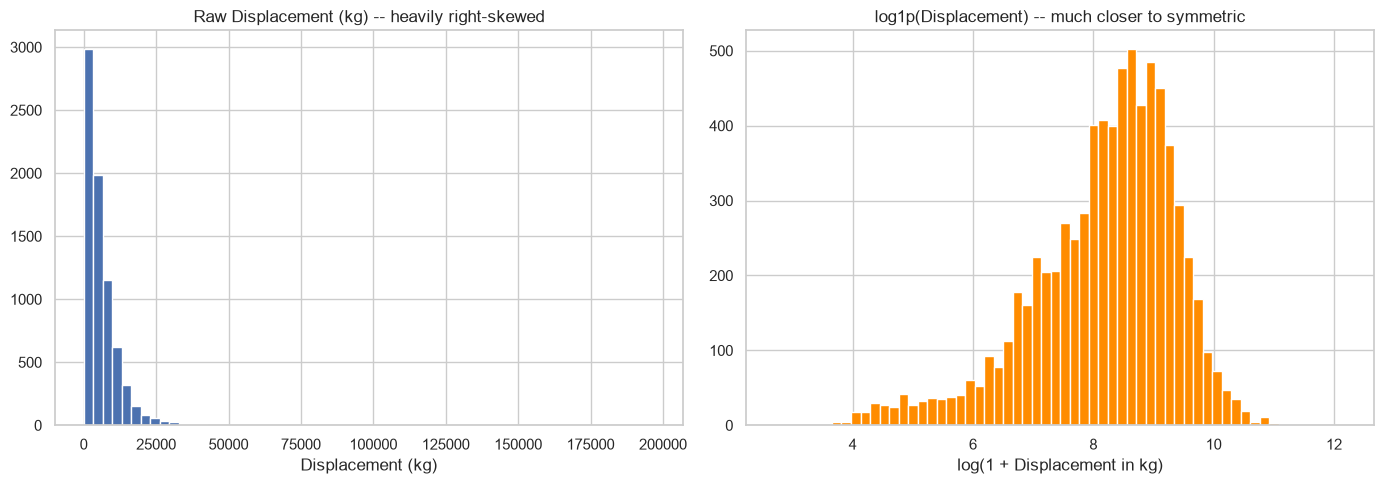

Raw Displacement spans 14,071x from smallest to largest boat -- exactly the kind of multi-order-of-magnitude spread that justifies modeling the log instead of the raw value.


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Displacement_kg"].hist(bins=60, ax=axes[0])
axes[0].set_title("Raw Displacement (kg) -- heavily right-skewed")
axes[0].set_xlabel("Displacement (kg)")

df["log_displacement"].hist(bins=60, ax=axes[1], color="darkorange")
axes[1].set_title("log1p(Displacement) -- much closer to symmetric")
axes[1].set_xlabel("log(1 + Displacement in kg)")

plt.tight_layout()
plt.show()

print(f"Raw Displacement spans {df['Displacement_kg'].max() / df['Displacement_kg'].min():,.0f}x "
      f"from smallest to largest boat -- exactly the kind of multi-order-of-magnitude "
      f"spread that justifies modeling the log instead of the raw value.")


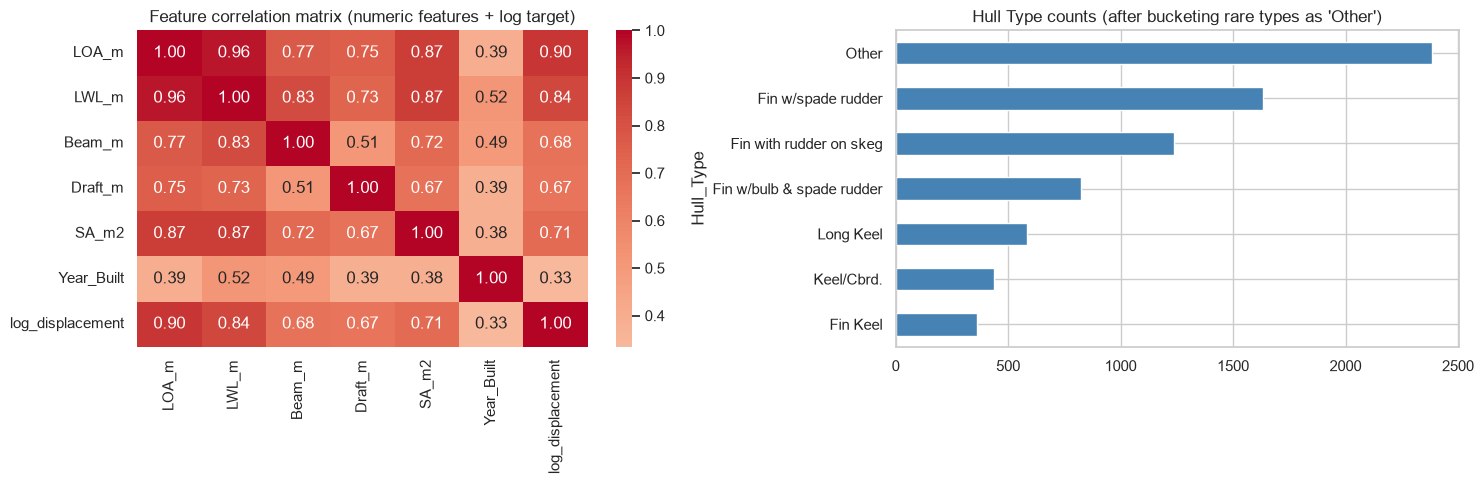

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

corr = df[numeric_features + ["log_displacement"]].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Feature correlation matrix (numeric features + log target)")

df["Hull_Type"].value_counts().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].invert_yaxis()
axes[1].set_title("Hull Type counts (after bucketing rare types as 'Other')")

plt.tight_layout()
plt.show()


`LOA_m` (length overall) and `Beam_m` correlate most strongly with log
displacement, which lines up with naval-architecture intuition — a boat's
displaced volume scales roughly with the product of its length, beam, and draft.
`Year_Built` has a mild negative correlation: newer boats tend to be built lighter
for a given size (modern construction materials and design trends), which is a
genuinely interesting signal for the models to pick up that the earlier two
datasets didn't have an analogue for.


## 3. Train / test split and preprocessing

With two real categorical columns in the mix, we need one more preprocessing step
than the previous two notebooks: encoding. We build **two** `ColumnTransformer`s
from the same train split:

- **`preprocess_scaled`** — standardizes the numeric features and one-hot encodes
  the categoricals. Used by Linear Regression, Ridge, Lasso, Elastic Net, and MLP
  (all scale-sensitive).
- **`preprocess_tree`** — leaves the numeric features unscaled (trees split on raw
  thresholds) but still one-hot encodes the categoricals, since Random Forest,
  XGBoost, and LightGBM all need purely numeric input. Used by those three.

**CatBoost gets neither** — it takes the original `X_train`/`X_test` untouched,
with `Hull_Type`/`Rigging_Type` passed as `cat_features` so it can use its native
categorical handling directly. This is the one dataset in this series where that
actually matters.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

preprocess_scaled = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_scaled = preprocess_scaled.fit_transform(X_train)
X_test_scaled = preprocess_scaled.transform(X_test)
scaled_feature_names = preprocess_scaled.get_feature_names_out()

preprocess_tree = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_enc = preprocess_tree.fit_transform(X_train)
X_test_enc = preprocess_tree.transform(X_test)
tree_feature_names = preprocess_tree.get_feature_names_out()

cat_feature_idx = [X_train.columns.get_loc(c) for c in categorical_features]

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Scaled/encoded feature count: {X_train_scaled.shape[1]}")
print(f"CatBoost categorical feature indices: {cat_feature_idx} ({categorical_features})")


Train: (5966, 8), Test: (1492, 8)
Scaled/encoded feature count: 19
CatBoost categorical feature indices: [6, 7] (['Hull_Type', 'Rigging_Type'])


In [7]:
results = {}  # model_name -> {"RMSE": ..., "MAE": ..., "R2": ...}  (all in log-displacement units)

def evaluate(name, y_true, y_pred):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2}
    print(f"{name:16s}  RMSE={rmse:.4f}   MAE={mae:.4f}   R2={r2:.4f}")
    return rmse, mae, r2


## 4. Linear Regression

Baseline, as always — a weighted sum of the standardized numeric features and
one-hot encoded categoricals. Given the naval-architecture intuition that
displacement scales *multiplicatively* with hull dimensions, and that we're
already modeling `log(displacement)` (which turns that multiplicative relationship
additive — `log(L × B × D) = log(L) + log(B) + log(D)`), we'd actually expect
Linear Regression to do reasonably well here, unlike on the housing dataset.


In [8]:
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)

y_pred_lr = lin_reg.predict(X_test_scaled)
evaluate("LinearRegression", y_test, y_pred_lr)


LinearRegression  RMSE=0.4488   MAE=0.3107   R2=0.8645


(0.44884557080326276, 0.3106852655859412, 0.8644949647442559)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/3850142378.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


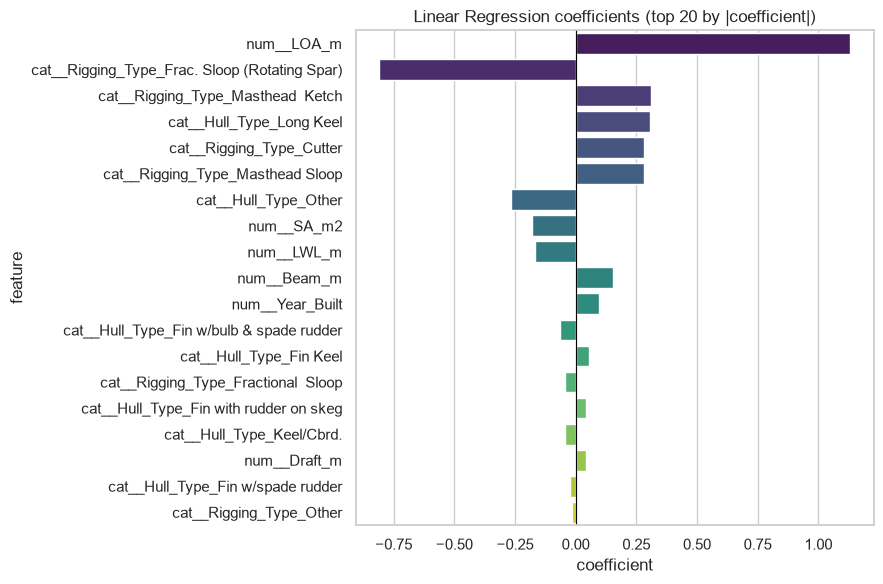

,feature,coefficient
0,num__LOA_m,1.132153
14,cat__Rigging_Type_Frac. Sloop (Rotating Spar),-0.810336
16,cat__Rigging_Type_Masthead Ketch,0.310027
11,cat__Hull_Type_Long Keel,0.304420
13,cat__Rigging_Type_Cutter,0.280797
17,cat__Rigging_Type_Masthead Sloop,0.280522
12,cat__Hull_Type_Other,-0.267822
4,num__SA_m2,-0.178758
1,num__LWL_m,-0.168847
2,num__Beam_m,0.152585


In [9]:
coef_df = pd.DataFrame({
    "feature": scaled_feature_names,
    "coefficient": lin_reg.coef_
}).sort_values("coefficient", key=abs, ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Linear Regression coefficients (top 20 by |coefficient|)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df


`LOA_m` and `Beam_m` dominate, exactly matching the correlation heatmap and the
naval-architecture intuition above. Watch for `Year_Built` showing up with a
negative coefficient — boats of a given length/beam have gotten lighter over the
decades, a genuinely new relationship the other two datasets had no equivalent of.


## 5. Regularized Linear Models: Ridge, Lasso & Elastic Net

`LOA_m` and `LWL_m` (length overall vs. waterline length) are naturally
correlated — both measure "how long is this boat," just slightly differently —
making this dataset a genuine candidate for regularization to actually matter
(more so than California Housing's weak multicollinearity). As before, `*CV`
variants pick `alpha`/`l1_ratio` automatically.


In [10]:
alphas = np.logspace(-2, 2, 3)

ridge = RidgeCV(alphas=alphas, cv=2)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)
evaluate("Ridge", y_test, y_pred_ridge)
print(f"Chosen alpha: {ridge.alpha_:.4f}")


Ridge             RMSE=0.4489   MAE=0.3107   R2=0.8644
Chosen alpha: 1.0000


In [11]:
lasso = LassoCV(alphas=alphas, cv=2, max_iter=5000, random_state=RANDOM_STATE)
lasso.fit(X_train_scaled, y_train)

y_pred_lasso = lasso.predict(X_test_scaled)
evaluate("Lasso", y_test, y_pred_lasso)
print(f"Chosen alpha: {lasso.alpha_:.4f}")
print(f"Features zeroed out: {(lasso.coef_ == 0).sum()} / {len(lasso.coef_)}")


Lasso             RMSE=0.4782   MAE=0.3272   R2=0.8462
Chosen alpha: 0.0100
Features zeroed out: 7 / 19


In [12]:
elastic = ElasticNetCV(
    alphas=alphas,
    l1_ratio=[.5],
    cv=2,
    max_iter=5000,
    random_state=RANDOM_STATE,
)
elastic.fit(X_train_scaled, y_train)

y_pred_elastic = elastic.predict(X_test_scaled)
evaluate("ElasticNet", y_test, y_pred_elastic)
print(f"Chosen alpha: {elastic.alpha_:.4f}, l1_ratio: {elastic.l1_ratio_:.2f}")
print(f"Features zeroed out: {(elastic.coef_ == 0).sum()} / {len(elastic.coef_)}")


ElasticNet        RMSE=0.4641   MAE=0.3188   R2=0.8551
Chosen alpha: 0.0100, l1_ratio: 0.50
Features zeroed out: 4 / 19


### Comparing coefficients across the four linear variants


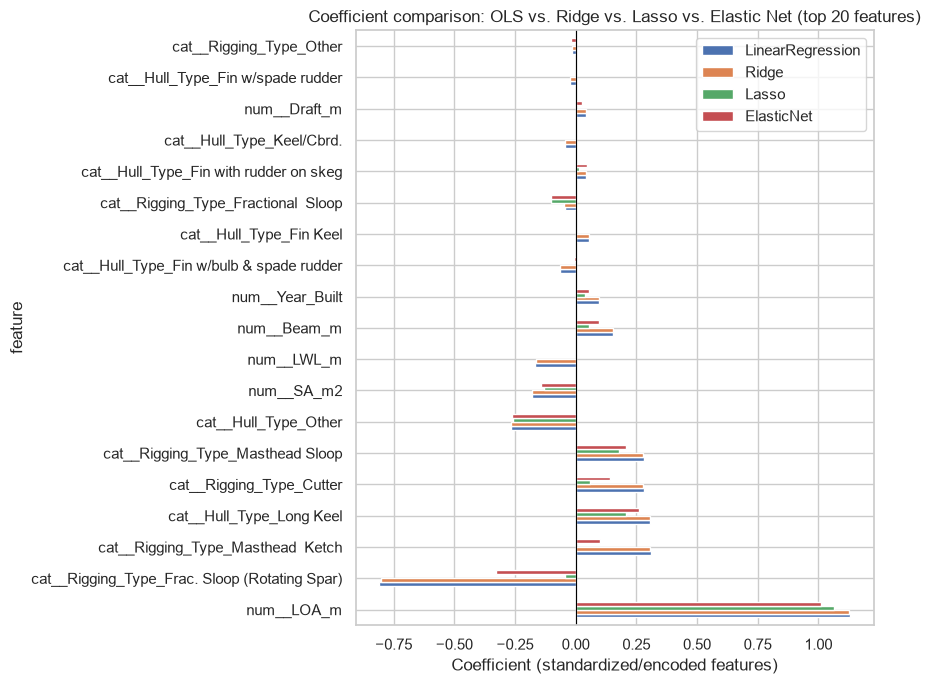

,LinearRegression,Ridge,Lasso,ElasticNet
feature,,,,
num__LOA_m,1.132153,1.127626,1.065945,1.009536
cat__Rigging_Type_Frac. Sloop (Rotating Spar),-0.810336,-0.801263,-0.042319,-0.330238
cat__Rigging_Type_Masthead Ketch,0.310027,0.307459,0.000000,0.098553
cat__Hull_Type_Long Keel,0.304420,0.304570,0.205145,0.261358
cat__Rigging_Type_Cutter,0.280797,0.278876,0.059436,0.142365
cat__Rigging_Type_Masthead Sloop,0.280522,0.279011,0.179651,0.205898
cat__Hull_Type_Other,-0.267822,-0.268457,-0.260078,-0.263834
num__SA_m2,-0.178758,-0.178394,-0.131628,-0.144449
num__LWL_m,-0.168847,-0.163964,0.000000,0.000000


In [13]:
coef_compare = pd.DataFrame({
    "feature": scaled_feature_names,
    "LinearRegression": lin_reg.coef_,
    "Ridge": ridge.coef_,
    "Lasso": lasso.coef_,
    "ElasticNet": elastic.coef_,
}).set_index("feature")

top_features = coef_compare["LinearRegression"].abs().sort_values(ascending=False).head(20).index
coef_compare.loc[top_features].plot(kind="barh", figsize=(9, 7))
plt.title("Coefficient comparison: OLS vs. Ridge vs. Lasso vs. Elastic Net (top 20 features)")
plt.xlabel("Coefficient (standardized/encoded features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_compare.loc[top_features]


Lasso/Elastic Net typically zero out several of the rarer one-hot encoded
`Hull_Type`/`Rigging_Type` categories here (and sometimes `LWL_m`, given its
correlation with `LOA_m`) while keeping `LOA_m` and `Beam_m` firmly in place —
again a good sign the models are picking up a real, physically-sensible signal.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's target by
averaging the targets of its `k` nearest training points in feature space —
"nearest" measured on the *scaled* features (the same `X_train_scaled`/
`X_test_scaled` used by the linear models and MLP above), since distance is
meaningless once features sit on wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [14]:
knn = KNeighborsRegressor(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
evaluate("KNN", y_test, y_pred_knn)


KNN               RMSE=0.2869   MAE=0.1930   R2=0.9446


(0.2869346659851518, 0.1930389499845721, 0.9446232343036014)

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [15]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsRegressor(),
    param_grid=knn_param_grid,
    cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV RMSE: {-knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 5, 'p': 2, 'weights': 'distance'}
Best CV RMSE: 0.3012


In [16]:
y_pred_knn_tuned = knn_grid.best_estimator_.predict(X_test_scaled)
evaluate("KNN (tuned)", y_test, y_pred_knn_tuned)


KNN (tuned)       RMSE=0.2858   MAE=0.1931   R2=0.9450


(0.2858497167322371, 0.1931268468149899, 0.945041220691632)

## 7. MLP (Multi-Layer Perceptron)

Same architecture search space as the previous two notebooks. With one-hot
encoded categoricals pushing the input dimensionality up to ~20+ features, the
network has a bit more to work with than before.


In [17]:
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)

y_pred_mlp = mlp.predict(X_test_scaled)
evaluate("MLP", y_test, y_pred_mlp)


MLP               RMSE=0.2634   MAE=0.1817   R2=0.9533


(0.26340704440778595, 0.1817235223699488, 0.9533323087140334)

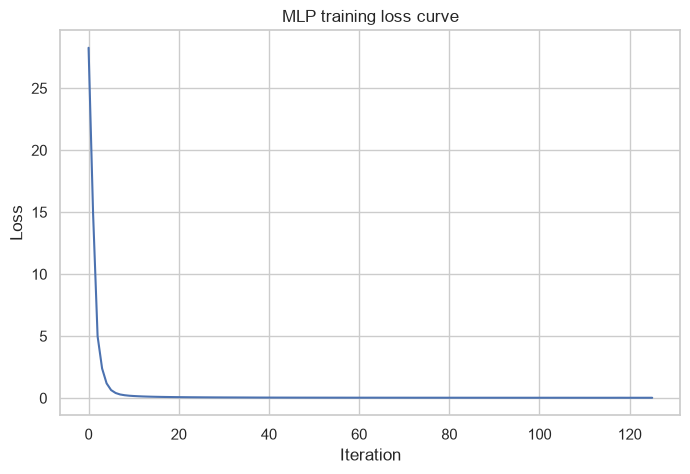

Stopped after 126 iterations (early_stopping=triggered)


In [18]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

print(f"Stopped after {len(mlp.loss_curve_)} iterations "
      f"(early_stopping={'triggered' if mlp.n_iter_ < mlp.max_iter else 'not triggered'})")


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [19]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPRegressor(
        activation="relu",
        learning_rate_init=1e-3,
        max_iter=500,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)

print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV RMSE: {-mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.0001}
Best CV RMSE: 0.2698


In [20]:
y_pred_mlp_tuned = mlp_search.best_estimator_.predict(X_test_scaled)
evaluate("MLP (tuned)", y_test, y_pred_mlp_tuned)


MLP (tuned)       RMSE=0.2634   MAE=0.1817   R2=0.9533


(0.26340704440778595, 0.1817235223699488, 0.9533323087140334)

## 8. Random Forest

Uses the unscaled-but-encoded feature set (`X_train_enc`) — trees don't need
scaling, but they do need the categoricals turned into numbers first.


In [21]:
rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf.fit(X_train_enc, y_train)

y_pred_rf = rf.predict(X_test_enc)
evaluate("RandomForest", y_test, y_pred_rf)


RandomForest      RMSE=0.2542   MAE=0.1730   R2=0.9565


(0.2542315411422066, 0.17300536424449772, 0.9565269204413807)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/1061948317.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


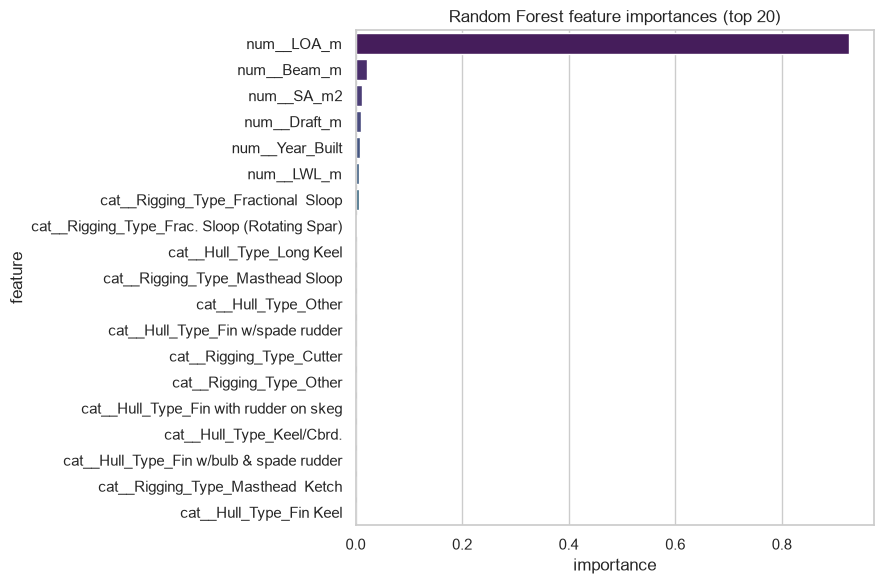

,feature,importance
0,num__LOA_m,0.926698
2,num__Beam_m,0.020895
4,num__SA_m2,0.012019
3,num__Draft_m,0.009387
5,num__Year_Built,0.007716
1,num__LWL_m,0.006998
15,cat__Rigging_Type_Fractional Sloop,0.005561
14,cat__Rigging_Type_Frac. Sloop (Rotating Spar),0.003448
11,cat__Hull_Type_Long Keel,0.001740
17,cat__Rigging_Type_Masthead Sloop,0.001213


In [22]:
rf_importance = pd.DataFrame({
    "feature": tree_feature_names,
    "importance": rf.feature_importances_
}).sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances (top 20)")
plt.tight_layout()
plt.show()

rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [23]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
rf_search.fit(X_train_enc, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV RMSE: {-rf_search.best_score_:.4f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV RMSE: 0.2767


In [24]:
y_pred_rf_tuned = rf_search.best_estimator_.predict(X_test_enc)
evaluate("RandomForest (tuned)", y_test, y_pred_rf_tuned)


RandomForest (tuned)  RMSE=0.2636   MAE=0.1821   R2=0.9532


(0.26364310304488536, 0.18207653969311935, 0.9532486264579703)

## 9. XGBoost (Extreme Gradient Boosting)

Same encoded feature set as Random Forest.


In [25]:
xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=2,
)
xgb.fit(
    X_train_enc, y_train,
    eval_set=[(X_test_enc, y_test)],
    verbose=False,
)

y_pred_xgb = xgb.predict(X_test_enc)
evaluate("XGBoost", y_test, y_pred_xgb)


XGBoost           RMSE=0.2468   MAE=0.1720   R2=0.9590


(0.24682100947882624, 0.17199422654751456, 0.9590243554206033)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/1149575576.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


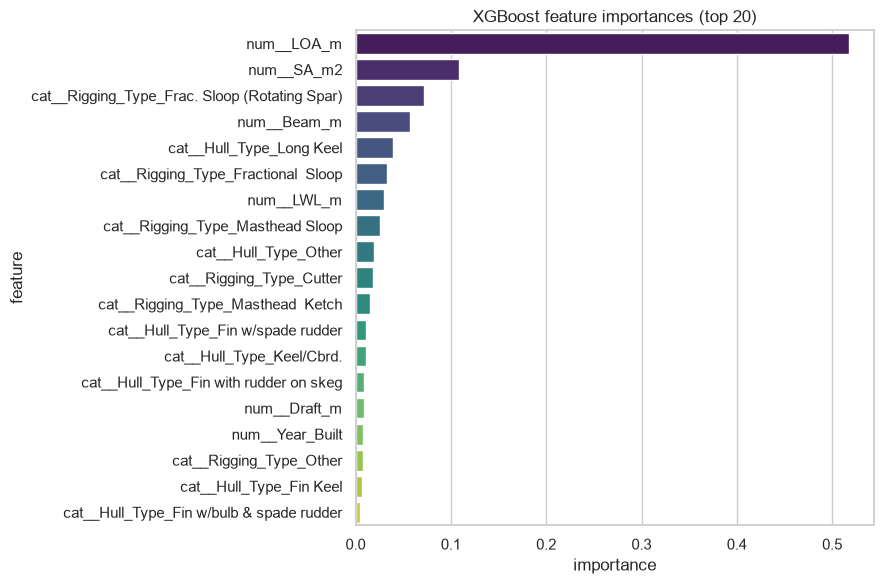

,feature,importance
0,num__LOA_m,0.518007
4,num__SA_m2,0.108136
14,cat__Rigging_Type_Frac. Sloop (Rotating Spar),0.071931
2,num__Beam_m,0.056647
11,cat__Hull_Type_Long Keel,0.039561
15,cat__Rigging_Type_Fractional Sloop,0.032578
1,num__LWL_m,0.029506
17,cat__Rigging_Type_Masthead Sloop,0.025858
12,cat__Hull_Type_Other,0.019252
13,cat__Rigging_Type_Cutter,0.018086


In [26]:
xgb_importance = pd.DataFrame({
    "feature": tree_feature_names,
    "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances (top 20)")
plt.tight_layout()
plt.show()

xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [27]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    param_distributions=xgb_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
xgb_search.fit(X_train_enc, y_train)

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV RMSE: {-xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05}
Best CV RMSE: 0.2501


In [28]:
y_pred_xgb_tuned = xgb_search.best_estimator_.predict(X_test_enc)
evaluate("XGBoost (tuned)", y_test, y_pred_xgb_tuned)


XGBoost (tuned)   RMSE=0.2468   MAE=0.1720   R2=0.9590


(0.24682100947882624, 0.17199422654751456, 0.9590243554206033)

## 10. CatBoost (Categorical Boosting)

**This is the section where CatBoost's headline feature finally matters.** Instead
of a one-hot encoded matrix, CatBoost gets the original `X_train`/`X_test` with
`Hull_Type` and `Rigging_Type` left as plain strings, declared via `cat_features`.
Internally it uses ordered target statistics instead of one-hot encoding — no
manual preprocessing, and it scales better than one-hot encoding would if these
columns had hundreds of categories instead of a handful.


In [29]:
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, cat_features=cat_feature_idx, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    use_best_model=True,
)

y_pred_cat = cat.predict(X_test)
evaluate("CatBoost", y_test, y_pred_cat)


CatBoost          RMSE=0.2497   MAE=0.1741   R2=0.9581


(0.24970354900677919, 0.17409666099244372, 0.9580616851700229)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/3227799930.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


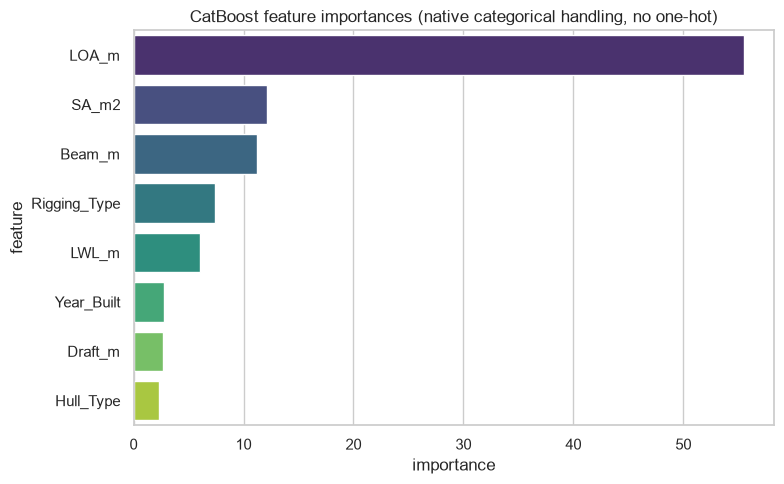

,feature,importance
0,LOA_m,55.469637
4,SA_m2,12.109467
2,Beam_m,11.200147
7,Rigging_Type,7.388691
1,LWL_m,6.023825
5,Year_Built,2.778711
3,Draft_m,2.687884
6,Hull_Type,2.341638


In [30]:
cat_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": cat.get_feature_importance()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances (native categorical handling, no one-hot)")
plt.tight_layout()
plt.show()

cat_importance


Notice `Hull_Type` and `Rigging_Type` each show up as a *single* row here,
with a real, substantial importance score — compare that to Random Forest/XGBoost's
charts above, where the same information is smeared across many separate
`cat__Hull_Type_...` one-hot columns, each individually looking less important than
it really is collectively. That's the concrete, visible payoff of native
categorical support on a dataset that actually has categoricals worth the name.


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [31]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostRegressor(
        l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE,
        thread_count=1, allow_writing_files=False,
        verbose=False,
    ),
    param_distributions=cat_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
# cat_features goes to .fit() here, not the constructor above -- CatBoostRegressor's
# sklearn wrapper doesn't round-trip cat_features through get_params()/set_params()
# cleanly, which breaks sklearn's clone() (used internally by RandomizedSearchCV).
# Passing it as a fit param instead sidesteps that entirely.
cat_search.fit(X_train, y_train, cat_features=cat_feature_idx)

print(f"Best params: {cat_search.best_params_}")
print(f"Best CV RMSE: {-cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV RMSE: 0.2536


In [32]:
y_pred_cat_tuned = cat_search.best_estimator_.predict(X_test)
evaluate("CatBoost (tuned)", y_test, y_pred_cat_tuned)


CatBoost (tuned)  RMSE=0.2497   MAE=0.1741   R2=0.9581


(0.2497125219104879, 0.17410745189088742, 0.9580586710741212)

## 11. LightGBM (Light Gradient Boosting Machine)

Back to the encoded feature set — LightGBM *can* take raw pandas categoricals
too (via `categorical_feature`), but we use the same one-hot encoding as
XGBoost/Random Forest here to keep a clean three-way comparison (CatBoost native
vs. everyone else one-hot) rather than a four-way mix of encoding schemes.


In [33]:
lgbm = LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbose=-1,
)
lgbm.fit(
    X_train_enc, y_train,
    eval_set=[(X_test_enc, y_test)],
)

y_pred_lgbm = lgbm.predict(X_test_enc)
evaluate("LightGBM", y_test, y_pred_lgbm)


LightGBM          RMSE=0.2481   MAE=0.1716   R2=0.9586


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.24807432584775257, 0.17157630637963336, 0.9586071637607116)

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/1970717563.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


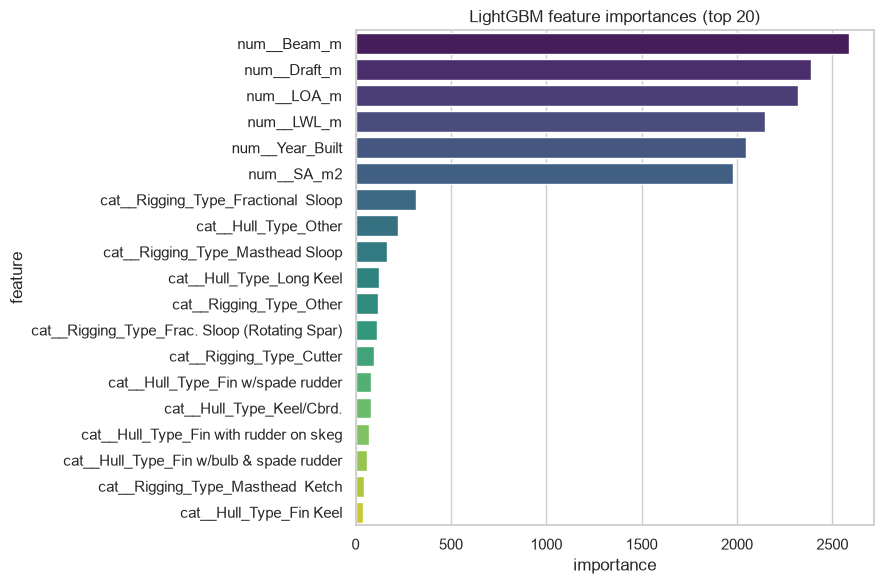

,feature,importance
2,num__Beam_m,2589
3,num__Draft_m,2389
0,num__LOA_m,2319
1,num__LWL_m,2145
5,num__Year_Built,2047
4,num__SA_m2,1977
15,cat__Rigging_Type_Fractional Sloop,319
12,cat__Hull_Type_Other,225
17,cat__Rigging_Type_Masthead Sloop,164
11,cat__Hull_Type_Long Keel,121


In [34]:
lgbm_importance = pd.DataFrame({
    "feature": tree_feature_names,
    "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False).head(20)

plt.figure(figsize=(9, 6))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances (top 20)")
plt.tight_layout()
plt.show()

lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [35]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMRegressor(
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_samples=20,
        random_state=RANDOM_STATE,
        n_jobs=2,
        verbose=-1,
    ),
    param_distributions=lgbm_param_dist,
    n_iter=2, cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=2,
    random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train_enc, y_train)

print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV RMSE: {-lgbm_search.best_score_:.4f}")


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV RMSE: 0.2541


In [36]:
y_pred_lgbm_tuned = lgbm_search.best_estimator_.predict(X_test_enc)
evaluate("LightGBM (tuned)", y_test, y_pred_lgbm_tuned)


LightGBM (tuned)  RMSE=0.2490   MAE=0.1722   R2=0.9583


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.24903434280815648, 0.17219038332792794, 0.9582861735500026)

## 12. Head-to-head comparison

All metrics below are in **log-displacement units** (natural log of kg, plus 1).
That makes RMSE/MAE harder to read as "kg of error" directly, but it's the right
space to *compare models* in, since it's what every model was actually trained to
minimize. The second scatter plot below also shows predictions back-transformed to
real kilograms, for interpretability.

Every boosted/ensemble model appears twice — baseline hyperparameters, and
`(tuned)` via the `RandomizedSearchCV` search in its section above — so you can see
directly how much tuning moved the needle. The log-space scatter plot shows only
the baseline (untuned) models, to keep it legible; the full tuned-vs-untuned
numbers are in the table and bar charts.


In [37]:
results_df = pd.DataFrame(results).T.sort_values("RMSE")
results_df


,RMSE,MAE,R2
XGBoost,0.246821,0.171994,0.959024
XGBoost (tuned),0.246821,0.171994,0.959024
LightGBM,0.248074,0.171576,0.958607
LightGBM (tuned),0.249034,0.172190,0.958286
CatBoost,0.249704,0.174097,0.958062
CatBoost (tuned),0.249713,0.174107,0.958059
RandomForest,0.254232,0.173005,0.956527
MLP,0.263407,0.181724,0.953332
MLP (tuned),0.263407,0.181724,0.953332
RandomForest (tuned),0.263643,0.182077,0.953249


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/2363801523.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/2363801523.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98093/2363801523.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, met

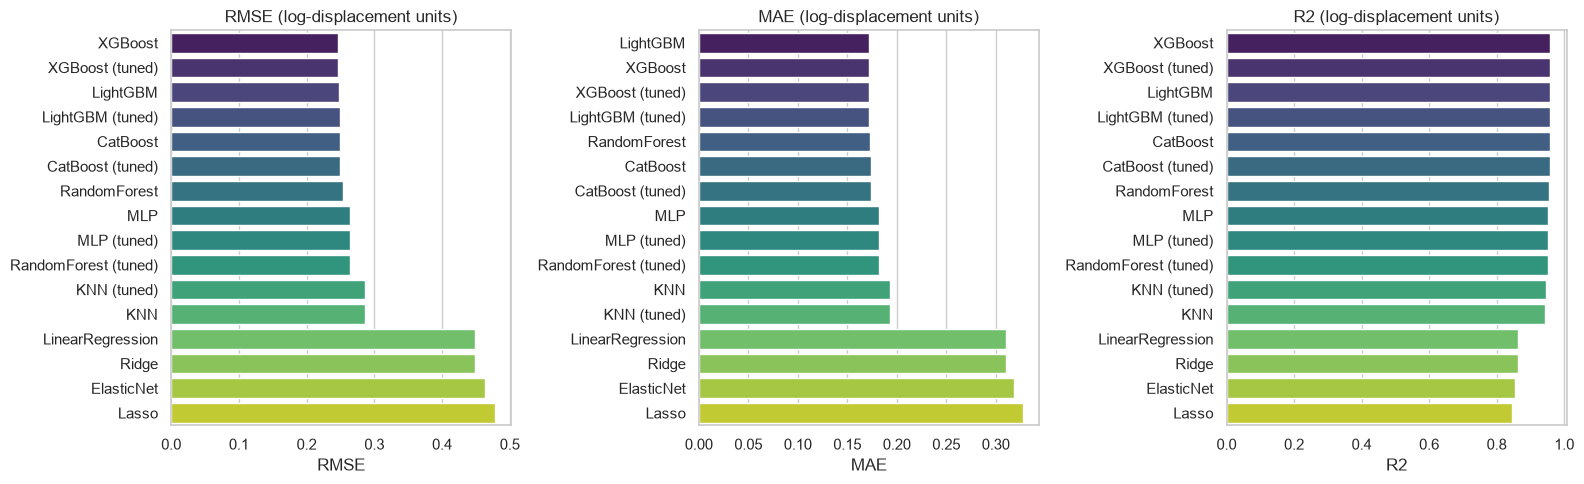

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    order = results_df.sort_values(metric, ascending=(metric != "R2")).index
    sns.barplot(x=results_df.loc[order, metric], y=order, palette="viridis", ax=ax)
    ax.set_title(f"{metric} (log-displacement units)")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


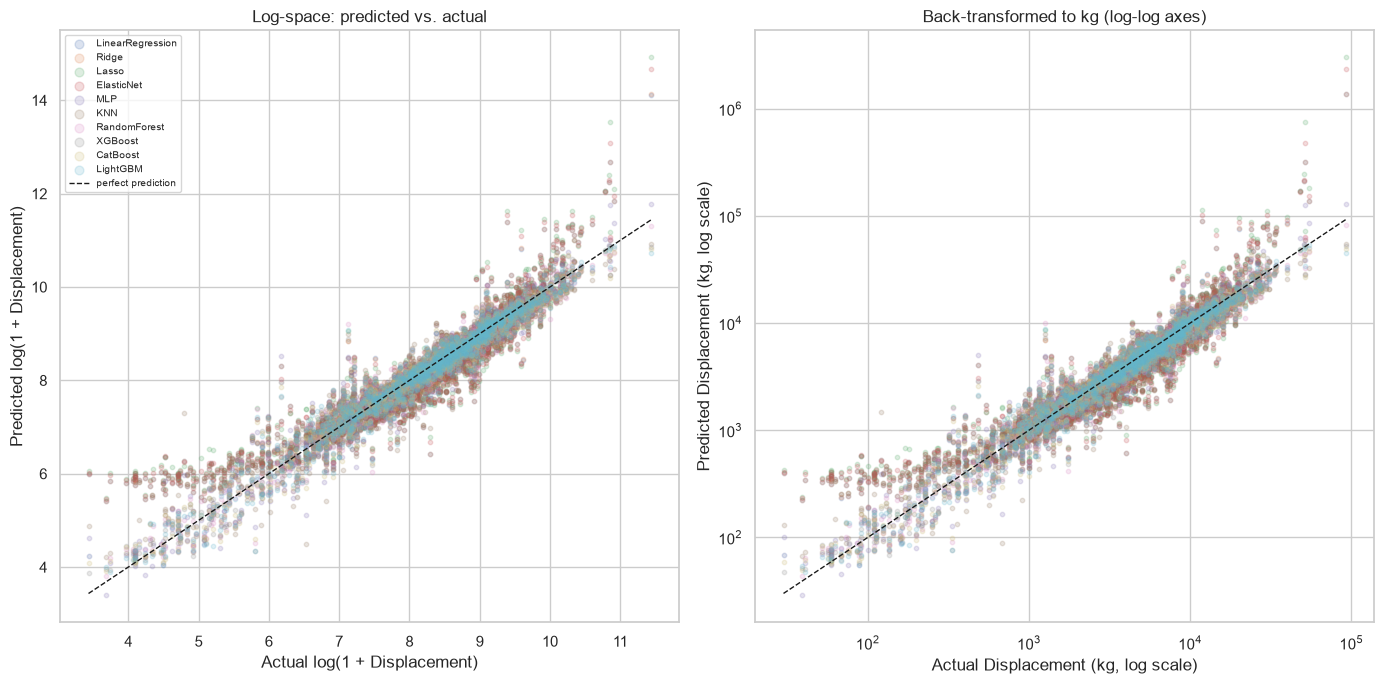

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

preds = {
    "LinearRegression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic,
    "MLP": y_pred_mlp,
    "KNN": y_pred_knn,
    "RandomForest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred_cat,
    "LightGBM": y_pred_lgbm,
}

ax = axes[0]
for name, p in preds.items():
    ax.scatter(y_test, p, alpha=0.2, s=10, label=name)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, "k--", linewidth=1, label="perfect prediction")
ax.set_xlabel("Actual log(1 + Displacement)")
ax.set_ylabel("Predicted log(1 + Displacement)")
ax.set_title("Log-space: predicted vs. actual")
ax.legend(markerscale=2, fontsize=7)

ax = axes[1]
y_test_kg = np.expm1(y_test)
for name, p in preds.items():
    ax.scatter(y_test_kg, np.expm1(p), alpha=0.2, s=10, label=name)
lims_kg = [y_test_kg.min(), y_test_kg.max()]
ax.plot(lims_kg, lims_kg, "k--", linewidth=1, label="perfect prediction")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Actual Displacement (kg, log scale)")
ax.set_ylabel("Predicted Displacement (kg, log scale)")
ax.set_title("Back-transformed to kg (log-log axes)")

plt.tight_layout()
plt.show()


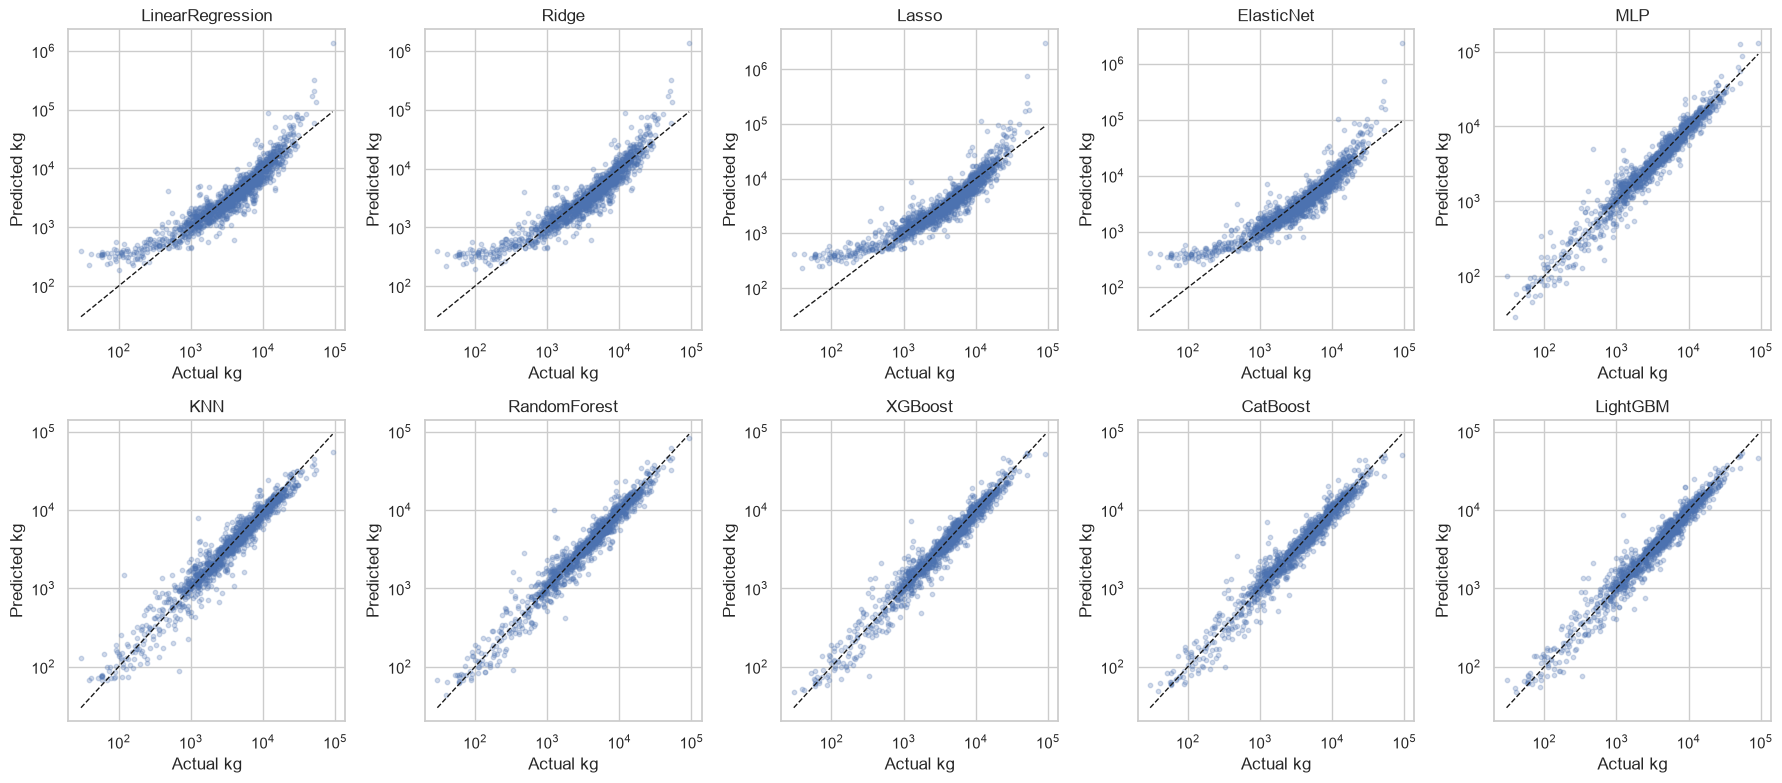

In [40]:
preds = {
    "LinearRegression": y_pred_lr,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso,
    "ElasticNet": y_pred_elastic,
    "MLP": y_pred_mlp,
    "KNN": y_pred_knn,
    "RandomForest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "CatBoost": y_pred_cat,
    "LightGBM": y_pred_lgbm,
}

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
y_test_kg = np.expm1(y_test)
lims_kg = [y_test_kg.min(), y_test_kg.max()]

for ax, (name, p) in zip(axes.ravel(), preds.items()):
    ax.scatter(y_test_kg, np.expm1(p), alpha=0.25, s=10)
    ax.plot(lims_kg, lims_kg, "k--", linewidth=1)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(name)
    ax.set_xlabel("Actual kg")
    ax.set_ylabel("Predicted kg")

plt.tight_layout()
plt.show()


The right-hand plot (back-transformed to real kilograms, on log-log axes)
is the more intuitive read: points hugging the diagonal across the *entire* size
range — from small dinghies to large yachts — confirm that modeling the log target
paid off. If we'd modeled raw kg directly, a few of the largest boats would have
dominated the loss and these models would likely have done noticeably worse on the
small end.


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [41]:
from sklearn.ensemble import StackingRegressor

stack = StackingRegressor(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=Ridge(alpha=1.0),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_pred_stack = stack.predict(X_test_scaled)
evaluate("Stacking", y_test, y_pred_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Stacking          RMSE=0.2446   MAE=0.1693   R2=0.9598


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


(0.2446004610158774, 0.16933745184173685, 0.9597583213978413)

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

In [42]:
final_results = pd.DataFrame(results).T.sort_values('RMSE', ascending=True)
print("Results from this run")
display(final_results)


Results from this run


,RMSE,MAE,R2
Stacking,0.244600,0.169337,0.959758
XGBoost (tuned),0.246821,0.171994,0.959024
XGBoost,0.246821,0.171994,0.959024
LightGBM,0.248074,0.171576,0.958607
LightGBM (tuned),0.249034,0.172190,0.958286
CatBoost,0.249704,0.174097,0.958062
CatBoost (tuned),0.249713,0.174107,0.958059
RandomForest,0.254232,0.173005,0.956527
MLP,0.263407,0.181724,0.953332
MLP (tuned),0.263407,0.181724,0.953332
